<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS03/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat kedua dataset dan menggabungkannya melalui 'cafe_id'
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

df = pd.merge(
    df_reviews,
    df_cafes,
    on='cafe_id',
    how='left',
    suffixes=('_review', '_cafe')
)

df.head()

,review_id,cafe_id,author_name,rating_review,text,published_at,likes,scraped_at_review,name,address,latitude,longitude,rating_cafe,review_count,categories,phone,website,scraped_at_cafe,source_query
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
2,6f1a2d5a-01c1-4fc9-8cfb-c4f5c8f58ec1,ba4b512c-fa2d-4959-8384-8570c81121ec,Nico Julianda,5.0,"comfort places for everything i did, mulai dar...",22 menit lalu,0,2026-10-11T13:54:49.854029,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
3,fd86734a-dcef-4f6d-8251-e47b203c0199,ba4b512c-fa2d-4959-8384-8570c81121ec,nazira parsa_04,5.0,"minumannya enak"", tempatnya comfy. worth to try",23 menit lalu,0,2026-10-11T13:54:49.967848,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
4,cdeda318-e583-4473-9fd0-4e4b48b56e16,ba4b512c-fa2d-4959-8384-8570c81121ec,dulkamdi dul,5.0,"kopian 24jam enak banget kalau dibuat wfc, tem...",28 menit lalu,0,2026-10-11T13:54:50.058719,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang


In [3]:
# Cek tipe data dan missing values
df.info()
print(df.isnull().sum())

# Imputasi data hilang pada kolom 'phone' dan 'website'
df['phone'] = df['phone'].fillna("TIDAK ADA")
df['website'] = df['website'].fillna("TIDAK ADA")

# Validasi hasil imputasi (0 missing values)
print("\nSetelah imputasi:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          2230 non-null   object 
 1   cafe_id            2230 non-null   object 
 2   author_name        2230 non-null   object 
 3   rating_review      2230 non-null   float64
 4   text               2230 non-null   object 
 5   published_at       2230 non-null   object 
 6   likes              2230 non-null   int64  
 7   scraped_at_review  2230 non-null   object 
 8   name               2230 non-null   object 
 9   address            2230 non-null   object 
 10  latitude           2230 non-null   float64
 11  longitude          2230 non-null   float64
 12  rating_cafe        2230 non-null   float64
 13  review_count       2230 non-null   int64  
 14  categories         2230 non-null   object 
 15  phone              2230 non-null   object 
 16  website            2230 

In [4]:
# === EKSTRAKSI FITUR ===

# 1. ReviewLength: jumlah kata pada teks ulasan
df["ReviewLength"] = df["text"].astype(str).apply(lambda x: len(x.split()))

# 2. Kecamatan: ekstrak nama kecamatan dari kolom address
df["Kecamatan"] = df["address"].str.extract(r'Kec\.\s*([^,]+)', expand=False).fillna("Lainnya")

# 3. PopularityBin: kelompokkan review_count menjadi kategori tingkat popularitas
df["PopularityBin"] = pd.cut(
    df["review_count"],
    bins=[0, 200, 1000, 3000, 10000],
    labels=["Sepi", "Sedang", "Ramai", "SangatRamai"]
)

# 4. CategoryClean: bersihkan format list string pada kolom categories
df["CategoryClean"] = df["categories"].astype(str).str.replace(r"[\[\]']", "", regex=True)

# 5. RatingDiff: selisih rating ulasan individu terhadap rata-rata rating kafe
df["RatingDiff"] = df["rating_review"] - df["rating_cafe"]

print("✅ Hasil Ekstraksi Fitur")
df[["name", "Kecamatan", "review_count", "PopularityBin", "ReviewLength", "CategoryClean", "RatingDiff"]].head()

✅ Hasil Ekstraksi Fitur


,name,Kecamatan,review_count,PopularityBin,ReviewLength,CategoryClean,RatingDiff
0,ARTE COFFEE & EATERY,Klojen,528,Sedang,1,Kedai Kopi,0.3
1,ARTE COFFEE & EATERY,Klojen,528,Sedang,25,Kedai Kopi,0.3
2,ARTE COFFEE & EATERY,Klojen,528,Sedang,20,Kedai Kopi,0.3
3,ARTE COFFEE & EATERY,Klojen,528,Sedang,7,Kedai Kopi,0.3
4,ARTE COFFEE & EATERY,Klojen,528,Sedang,12,Kedai Kopi,0.3


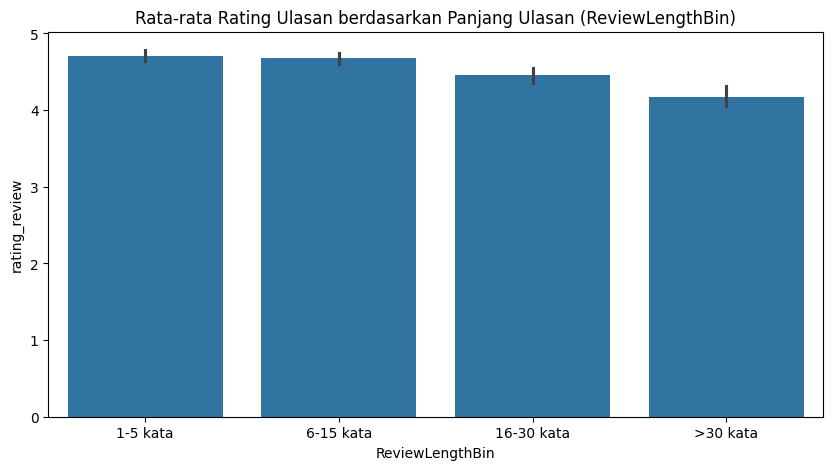

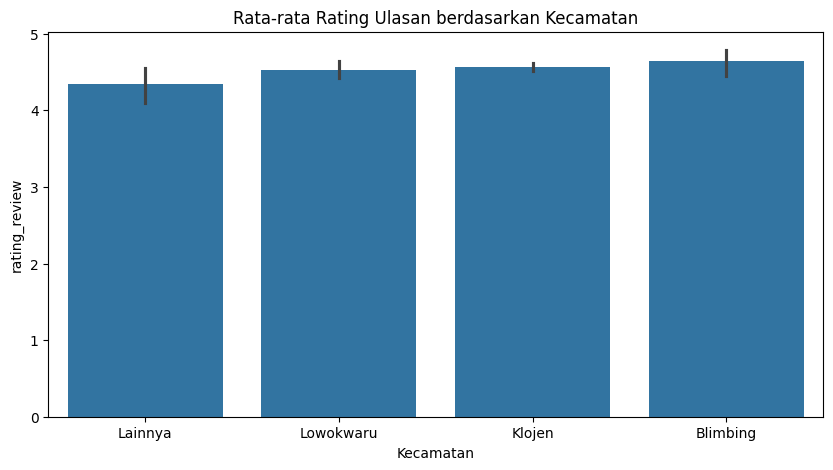

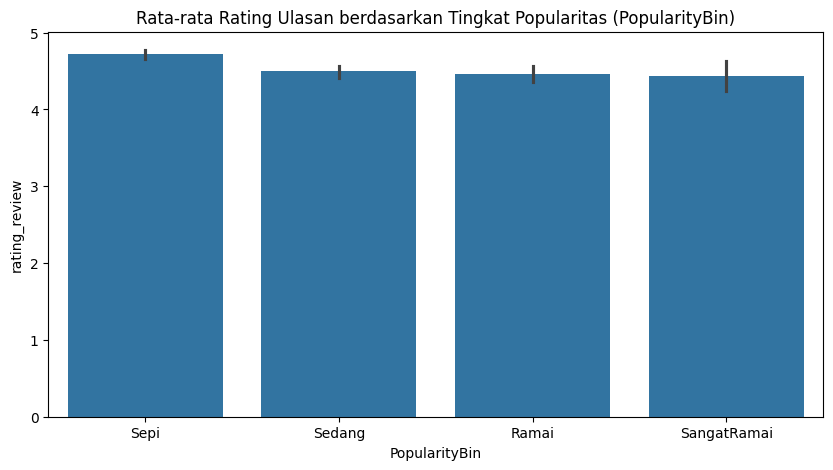

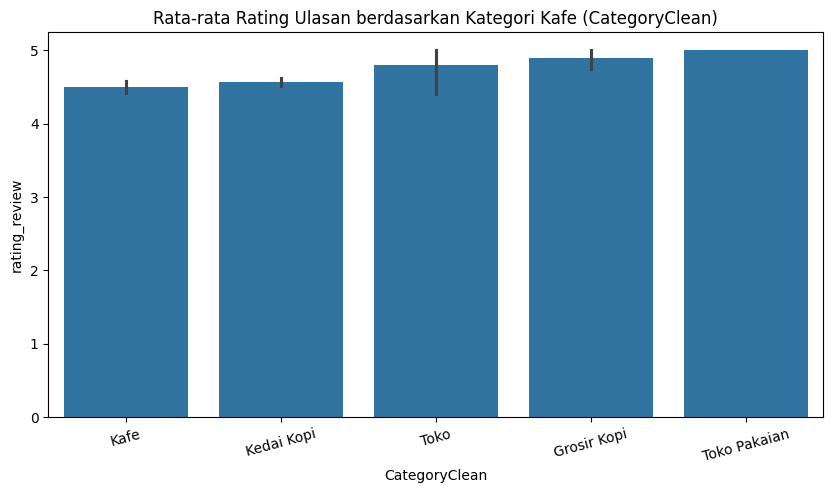

In [5]:
# Tambahan binning panjang ulasan agar grafik barplot rapi
df["ReviewLengthBin"] = pd.cut(
    df["ReviewLength"],
    bins=[0, 5, 15, 30, 500],
    labels=["1-5 kata", "6-15 kata", "16-30 kata", ">30 kata"]
)

# 1. Rating berdasarkan Panjang Ulasan
plt.figure(figsize=(10, 5))
sns.barplot(x="ReviewLengthBin", y="rating_review", data=df)
plt.title("Rata-rata Rating Ulasan berdasarkan Panjang Ulasan (ReviewLengthBin)")
plt.show()

# 2. Rating berdasarkan Kecamatan
plt.figure(figsize=(10, 5))
sns.barplot(x="Kecamatan", y="rating_review", data=df,
            order=df.groupby("Kecamatan")["rating_review"].mean().sort_values().index)
plt.title("Rata-rata Rating Ulasan berdasarkan Kecamatan")
plt.show()

# 3. Rating berdasarkan Tingkat Popularitas
plt.figure(figsize=(10, 5))
sns.barplot(x="PopularityBin", y="rating_review", data=df,
            order=["Sepi", "Sedang", "Ramai", "SangatRamai"])
plt.title("Rata-rata Rating Ulasan berdasarkan Tingkat Popularitas (PopularityBin)")
plt.show()

# 4. Rating berdasarkan Kategori Kafe
plt.figure(figsize=(10, 5))
sns.barplot(x="CategoryClean", y="rating_review", data=df,
            order=df.groupby("CategoryClean")["rating_review"].mean().sort_values().index)
plt.title("Rata-rata Rating Ulasan berdasarkan Kategori Kafe (CategoryClean)")
plt.xticks(rotation=15)
plt.show()